# 04 · Features and preprocessing

**Question:** do the whitelisted features behave as intended, does any of them see the
future, and how far do they drift between training, validation and test months?

**Out:** `data/processed/model_table.parquet`, one row per accident with the label, the
split and the 31 features. Every later notebook starts from it.

The features come from `features.build_model_table`, the single implementation shared
with the dashboard export.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from accidents import clean, config, evaluate, features, ingest, plots, split

plots.use_style()
pd.set_option("display.width", 140)

## 1 · Build the model table

The location history needs one number from the labels: the overall Severity-4 rate that
smooths small cells. It is taken from **training months only**, so no validation or test
label shapes any feature.

In [2]:
population = clean.mask_impossible_readings(
    clean.target_window(ingest.read_parquet(ingest.POPULATION_COLUMNS, ingest.POPULATION_ROWS))
)
splits = split.assign_split(population["Start_Time"])
prior_rate = float(population.loc[splits == "train", "y"].mean())
print(f"prior rate (training months): {prior_rate:.4f}")

table = features.build_model_table(population, prior_rate)
table["split"] = pd.Categorical(splits, categories=split.SPLITS)
table.to_parquet(config.MODEL_TABLE, index=False)
print(f"{len(table):,} rows × {table.shape[1]} columns → {config.MODEL_TABLE.name}")

summary = table.groupby("split", observed=True).agg(
    rows=("y", "size"), severity4=("y", "sum"), rate=("y", "mean"),
    first=("start_time", "min"), last=("start_time", "max"),
)  # fmt: skip
display(summary)

prior rate (training months): 0.0246


3,242,942 rows × 36 columns → model_table.parquet


,rows,severity4,rate,first,last
split,,,,,
burn_in,356371,6908,0.019384,2020-10-01 00:00:00,2020-12-31 23:59:31
train,1460553,35983,0.024637,2021-01-01 00:00:00,2022-03-31 23:59:28
valid,774383,22031,0.028450,2022-04-01 00:00:20,2022-09-30 23:59:42
test,651635,18116,0.027801,2022-10-01 00:00:00,2023-03-31 23:30:00


## 2 · Feature types and missing values

Missing weather readings stay missing (notebook 02: missingness carries signal). Gradient
boosting handles them natively; linear and neural models get missing-value flags in their
own preprocessing (notebook 05).

In [3]:
overview = pd.DataFrame(
    {
        "dtype": table[features.FEATURES].dtypes.astype(str),
        "missing_%": (table[features.FEATURES].isna().mean() * 100).round(2),
        "distinct": table[features.FEATURES].nunique(),
    }
)
display(overview)

,dtype,missing_%,distinct
lat,float64,0.00,1234095
lng,float64,0.00,1256667
temperature_f,float64,2.47,163
humidity_pct,float64,2.63,100
pressure_in,float64,2.15,1060
visibility_mi,float64,2.58,35
wind_speed_mph,float64,2.95,78
precipitation_in,float64,4.32,212
hour,int8,0.00,24
weekday,int8,0.00,7


## 3 · The location history sees only the past

`cell_count` and `cell_rate` summarise the accidents in the same 0.25° grid cell
(about 28 × 23 km) over the previous 365 days, excluding the accident's own day.
`tests/test_features.py` proves the past-only rule on constructed data. Here are two checks
on the real table: the history fills up during the burn-in quarter, and a higher past rate
goes with a higher current rate.

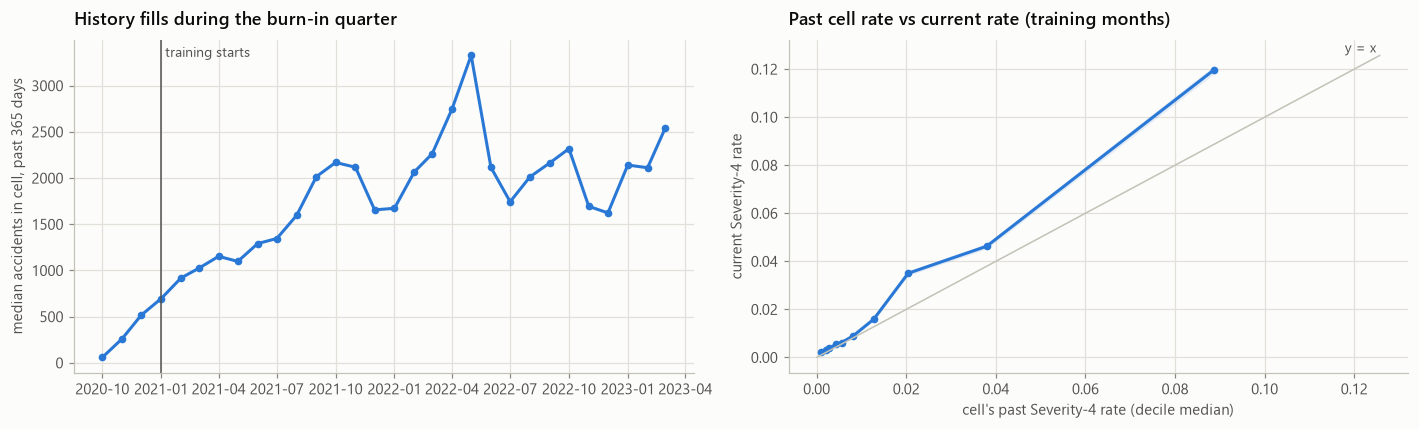

,n,positives,rate,low,high
cell_rate,,,,,
"(-0.000843, 0.00143]",146077,307,0.0021,0.0019,0.0023
"(0.00143, 0.00238]",146074,435,0.0030,0.0027,0.0033
"(0.00238, 0.00356]",146110,555,0.0038,0.0035,0.0041
"(0.00356, 0.00486]",146070,790,0.0054,0.0050,0.0058
"(0.00486, 0.00659]",145951,904,0.0062,0.0058,0.0066
"(0.00659, 0.0101]",146628,1320,0.0090,0.0085,0.0095
"(0.0101, 0.0159]",145552,2320,0.0159,0.0153,0.0166
"(0.0159, 0.0262]",146049,5115,0.0350,0.0341,0.0360
"(0.0262, 0.0554]",146092,6763,0.0463,0.0452,0.0474


In [4]:
calendar_month = table["start_time"].dt.to_period("M")  # not the `month` feature
fill = table["cell_count"].groupby(calendar_month).median()
train = table[table["split"] == "train"]
deciles = pd.qcut(train["cell_rate"], 10, duplicates="drop")
by_decile = evaluate.rate_table(train["y"], deciles)
centres = train.groupby(deciles, observed=True)["cell_rate"].median()

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
left.plot(fill.index.to_timestamp(), fill.values, color=plots.SERIES[0], marker="o", markersize=4)
left.axvline(pd.Timestamp(config.TRAIN_START), color=plots.INK_SECONDARY, linewidth=1)
left.text(
    pd.Timestamp(config.TRAIN_START),
    0.95,
    " training starts",
    transform=left.get_xaxis_transform(),
    color=plots.INK_SECONDARY,
    fontsize=9,
)
left.set_ylabel("median accidents in cell, past 365 days")
left.set_title("History fills during the burn-in quarter")
right.fill_between(
    centres, by_decile["low"], by_decile["high"], color=plots.SERIES[0], alpha=0.12, linewidth=0
)
right.plot(centres, by_decile["rate"], color=plots.SERIES[0], marker="o", markersize=4)
lim = max(centres.max(), by_decile["rate"].max()) * 1.05
right.plot([0, lim], [0, lim], color=plots.BASELINE, linewidth=1)
right.text(lim, lim, "y = x ", ha="right", va="bottom", color=plots.INK_SECONDARY, fontsize=9)
right.set_xlabel("cell's past Severity-4 rate (decile median)")
right.set_ylabel("current Severity-4 rate")
right.set_title("Past cell rate vs current rate (training months)")
plt.tight_layout()
plt.show()
display(by_decile.round(4))

## 4 · Drift between splits

Population stability index (PSI) of each feature in validation and test months against
training months. Below 0.1 is stable, 0.1–0.25 a moderate shift and above 0.25 a large one.
Drift is expected for `month` (the splits cover different seasons) and for `cell_count`
(traffic-feed volume grew over time).

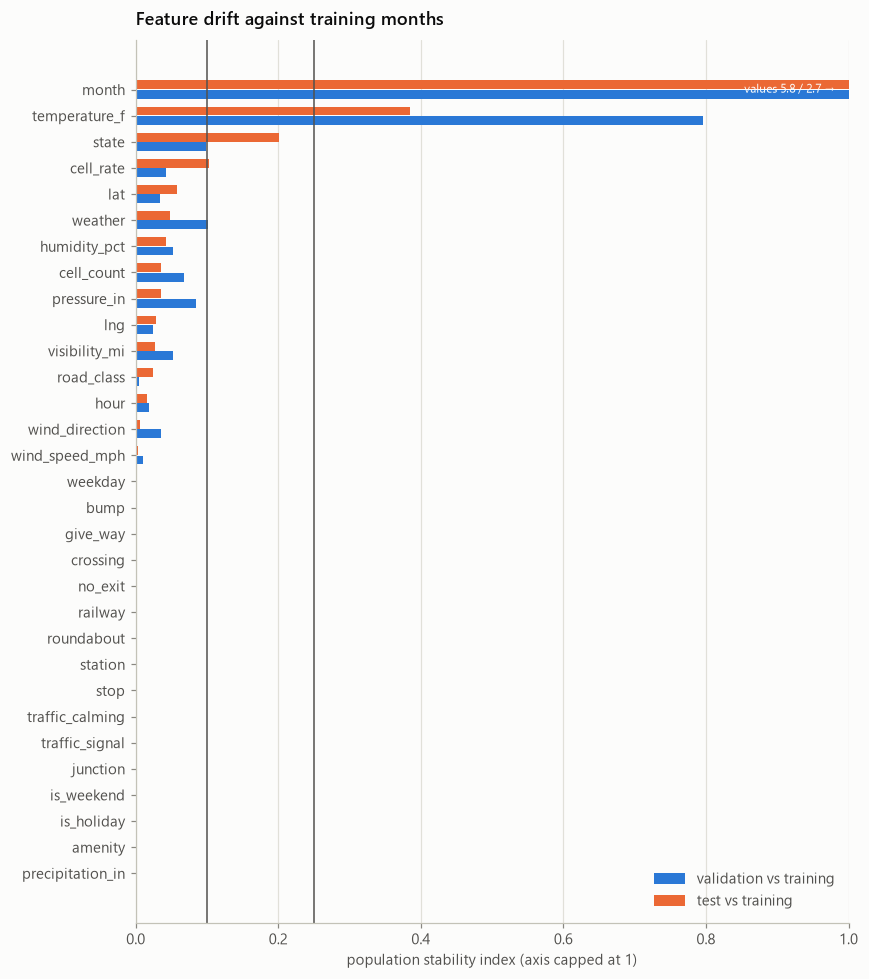

,valid vs train,test vs train
weather,0.101,0.047
cell_rate,0.042,0.102
state,0.098,0.201
temperature_f,0.796,0.385
month,5.843,2.686


In [5]:
valid = table[table["split"] == "valid"]
test = table[table["split"] == "test"]
psi = pd.DataFrame(
    {
        "valid vs train": {
            f: evaluate.population_stability(train[f], valid[f]) for f in features.FEATURES
        },
        "test vs train": {
            f: evaluate.population_stability(train[f], test[f]) for f in features.FEATURES
        },
    }
).sort_values("test vs train")

fig, ax = plt.subplots(figsize=(8, 9))
yy = np.arange(len(psi))
ax.barh(
    yy - 0.18,
    psi["valid vs train"],
    height=0.34,
    color=plots.SERIES[0],
    label="validation vs training",
)
ax.barh(
    yy + 0.18, psi["test vs train"], height=0.34, color=plots.SERIES[1], label="test vs training"
)
for threshold in (0.1, 0.25):
    ax.axvline(threshold, color=plots.INK_SECONDARY, linewidth=1)
cap = 1.0  # month drifts by design (the splits cover different seasons); label it instead
ax.set_xlim(0, cap)
for row, name in enumerate(psi.index):
    clipped = [f"{psi.loc[name, c]:.1f}" for c in psi.columns if psi.loc[name, c] > cap]
    if clipped:
        ax.text(
            cap * 0.98,
            row,
            "values " + " / ".join(clipped) + " →",
            ha="right",
            va="center",
            fontsize=8,
            color=plots.SURFACE,
        )
ax.set_yticks(yy, psi.index)
ax.set_xlabel("population stability index (axis capped at 1)")
ax.set_title("Feature drift against training months")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(psi[psi.max(axis=1) >= 0.1].round(3))

## Decisions and evidence

- **The table:** 3,242,942 rows. Burn-in 356,371 (history only), train 1,460,553
  (Severity-4 rate 2.46%), validation 774,383 (2.85%), test 651,635 (2.78%). The smoothing
  prior (2.46%) comes from training months only.
- **Missing values stay missing:** 2.2–4.3% of each weather reading, no other feature has
  gaps. Categories use fixed lists (49 states, 5 road classes, 7 weather classes, 19 wind
  directions), so training and the dashboard share one encoding.
- **The location history works and is past-only:** the median history fills from almost
  nothing to about 700 accidents per cell by the time training starts. A cell's past rate
  orders the current rate cleanly, from 0.21% in its lowest decile to 12.0% in its highest.
  The top deciles sit above the y = x line: smoothing pulls small cells towards the prior,
  and the model will learn the rest.
- **Drift:** large only where expected. `month` (PSI 5.8 validation, 2.7 test) and
  `temperature_f` (0.80, 0.39) follow the seasons the splits cover. `state` shifts
  moderately on test (0.20) as the feed's coverage changes, and `cell_rate` reaches 0.10 on
  test. Every other feature stays below 0.1. → Season effects are learned from one or two
  years only, and the test split covers autumn and winter. Notebook 06 checks performance by
  month and by state, and notebook 07 reads the `month` effect with care.
- Next: notebook 05 benchmarks eight model families on this table.